# STEP 4. Basic EDA

We check that the panel built so far is **sensible data** and sketch the outline of the later steps. No conclusions are drawn here; we only decide where to dig.

| Section | What we look at | Which question it previews |
|---|---|---|
| 4-1 | Sample composition | — |
| 4-2 | Net decline rate by service category | **H2** treated-group candidate |
| 4-3 | Net decline rate by district | **Core question** |
| 4-4 | Commercial area type × service category | **H1** |
| 4-5 | Distribution and log transform | Matching stability |
| 4-6 | Covariate correlation · VIF | Propensity score model |
| 4-7 | Net decline rate by feature | **Sub-question 2** |

> ⚠️ In STEP 3 the store-count basis changed to the total count, which grew the sample by 20.9%, and the inflow is concentrated in franchise-dense service categories. **The service-category ranking may differ from earlier runs.**

In [1]:
import sys, os
from pathlib import Path

# Find the project root wherever the notebook is opened and add it to sys.path
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print("Project root:", ROOT.name)

Project root: seoul-closure-risk


In [2]:
import matplotlib.pyplot as plt
from config import PROC, FIG, FOOD, TARGET_TYPE, COVARIATES, set_plot_style
set_plot_style()
OUT = FIG.parent

d = pd.read_pickle(PROC / "03_panel.pkl")

# Clean up the temporary column from STEP 2 if it is still there (same information as sales_observed)
d = d.drop(columns=[c for c in ["sales_missing_flag"] if c in d.columns])

gm = d[d["area_type"] == TARGET_TYPE]
print(f"Panel {d.shape} | net decline rate {d['y'].mean():.1%}")
print(f"{TARGET_TYPE} {len(gm):,} rows | net decline rate {gm['y'].mean():.1%}")

Panel (67475, 34) | net decline rate 25.5%
neighborhood commercial area 34,647 rows | net decline rate 23.6%


## 4-1. Sample composition

**The tourist special zone has only 6 commercial areas.** The cell count looks like several hundred, but there are only 6 independent commercial areas, so no figure from it is used as a separate conclusion.

In [3]:
t = (d.groupby("area_type")
     .agg(n_cells=("y", "size"), n_areas=("area_code", "nunique"),
          net_decline_rate=("y", "mean"), mean_stores=("store_count", "mean"),
          median_foot_traffic=("foot_traffic_total", "median"))
     .sort_values("net_decline_rate", ascending=False))
display(t.round(3))
print("Note: the tourist special zone has only 6 commercial areas, so no conclusion is drawn regardless of the cell count.")

display(d.groupby("quarter_code")
        .agg(n_cells=("y", "size"), net_decline_rate=("y", "mean")).round(3).T)

,n_cells,n_areas,net_decline_rate,mean_stores,median_foot_traffic
area_type,,,,,
tourist special zone,696,6,0.378,90.986,4005509.0
developed commercial area,23011,248,0.292,33.332,1214182.0
neighborhood commercial area,34647,928,0.236,13.454,1019353.0
traditional market,9121,240,0.224,15.957,434783.0


Note: the tourist special zone has only 6 commercial areas, so no conclusion is drawn regardless of the cell count.


quarter_code,20231,20232,20233,20234,20241,20242,20243,20244,20251,20252,20253,20254
n_cells,5706.000,5731.000,5701.000,5730.000,5706.000,5678.000,5622.000,5586.000,5534.000,5502.00,5500.000,5479.00
net_decline_rate,0.229,0.261,0.223,0.236,0.254,0.276,0.262,0.284,0.261,0.26,0.253,0.26


## 4-2. Net decline rate by service category — H2 treated-group candidate

In STEP 5 the **highest-rate service category is assigned as the treated group automatically**. We let the data choose instead of fixing it in advance to avoid any impression that it was picked arbitrarily. Here we preview what that candidate will be.

In [4]:
def by_svc(frame, label):
    return (frame.groupby("service_name")
            .agg(**{f"{label}_net_decline_rate": ("y", "mean"), f"{label}_n_cells": ("y", "size")}))

t = by_svc(d, "all").join(by_svc(gm, "neighborhood"))
t = t.sort_values("neighborhood_net_decline_rate", ascending=False)
display(t.round(3))

print(f"→ {TARGET_TYPE} highest-risk service category: {t.index[0]} ({t.iloc[0]['neighborhood_net_decline_rate']:.1%})")
print(f"   2nd: {t.index[1]} ({t.iloc[1]['neighborhood_net_decline_rate']:.1%}), gap "
      f"{(t.iloc[0]['neighborhood_net_decline_rate']-t.iloc[1]['neighborhood_net_decline_rate'])*100:+.1f} pp")
print("\nNote: a small gap means the treated-group choice is sensitive to sampling variation; to be checked in STEP 5")

,all_net_decline_rate,all_n_cells,neighborhood_net_decline_rate,neighborhood_n_cells
service_name,,,,
Korean restaurants,0.269,15677,0.253,9957
Coffee and beverages,0.263,12046,0.244,7741
Beer and casual pubs,0.289,8448,0.239,4596
Fast-food restaurants,0.239,3901,0.237,1440
Western restaurants,0.266,4172,0.228,1478
Korean snack-food restaurants,0.236,7570,0.222,3634
Japanese restaurants,0.256,3696,0.216,1036
Bakeries,0.225,4133,0.206,1636
Fried-chicken shops,0.205,4186,0.201,1922


→ neighborhood commercial area highest-risk service category: Korean restaurants (25.3%)
   2nd: Coffee and beverages (24.4%), gap +0.9 pp

Note: a small gap means the treated-group choice is sensitive to sampling variation; to be checked in STEP 5


### Do size and risk move together

We look at the correlation between a service category's average store count and its net decline rate. **If the correlation is high, it is likely a "size difference" rather than a "category-specific risk".** This is exactly what H2 tries to separate.

In [5]:
prof = (gm.groupby("service_name")
        .agg(net_decline_rate=("y", "mean"), mean_stores=("store_count", "mean"),
             median_foot_traffic=("foot_traffic_total", "median"),
             mean_franchise_share=("franchise_share", "mean"),
             n_cells=("y", "size")))
r = np.corrcoef(prof["mean_stores"], prof["net_decline_rate"])[0, 1]
r2 = np.corrcoef(prof["mean_franchise_share"], prof["net_decline_rate"])[0, 1]
display(prof.sort_values("net_decline_rate", ascending=False).round(3))
print(f"Category mean store count  <-> net decline rate   r = {r:+.3f}")
print(f"Category franchise share  <-> net decline rate  r = {r2:+.3f}")

,net_decline_rate,mean_stores,median_foot_traffic,mean_franchise_share,n_cells
service_name,,,,,
Korean restaurants,0.253,21.315,779241.0,0.097,9957
Coffee and beverages,0.244,12.595,893978.0,0.181,7741
Beer and casual pubs,0.239,11.783,1170658.0,0.092,4596
Fast-food restaurants,0.237,7.090,1515928.5,0.502,1440
Western restaurants,0.228,11.118,1305611.5,0.068,1478
Korean snack-food restaurants,0.222,8.234,1264523.0,0.201,3634
Japanese restaurants,0.216,8.420,1549588.5,0.122,1036
Bakeries,0.206,7.411,1319055.5,0.161,1636
Fried-chicken shops,0.201,6.703,1391462.5,0.642,1922


Category mean store count  <-> net decline rate   r = +0.657
Category franchise share  <-> net decline rate  r = -0.201


## 4-3. Net decline rate by district — preview of the core question

**Core question**: which food-service categories will turn into a net store decline next quarter, by district?

Here we pick the highest-risk service category per district on the neighborhood commercial area basis. However, **splitting by district × service category thins out the cells**, so we always look at the sample sizes alongside.

In [6]:
gu = (gm.groupby("district")
      .agg(n_cells=("y", "size"), n_areas=("area_code", "nunique"), net_decline_rate=("y", "mean"))
      .sort_values("net_decline_rate", ascending=False))
display(gu.round(3))
print(f"Net decline rate range across districts {gu['net_decline_rate'].min():.1%} ~ {gu['net_decline_rate'].max():.1%} "
      f"(gap {(gu['net_decline_rate'].max()-gu['net_decline_rate'].min())*100:.1f} pp)")

,n_cells,n_areas,net_decline_rate
district,,,
Gwanak-gu,1849,43,0.267
Gangseo-gu,1857,45,0.266
Dobong-gu,1055,27,0.264
Gangdong-gu,1735,39,0.252
Seongdong-gu,1171,33,0.250
Jungnang-gu,1676,44,0.249
Guro-gu,1423,35,0.249
Dongdaemun-gu,1561,43,0.246
Gangbuk-gu,1093,38,0.244


Net decline rate range across districts 17.5% ~ 26.7% (gap 9.2 pp)


In [7]:
cell = (gm.groupby(["district", "service_name"])
        .agg(net_decline_rate=("y", "mean"), n_cells=("y", "size")).reset_index())
MIN_CELL = 100     # cells thinner than this are excluded from the ranking
top = (cell[cell["n_cells"] >= MIN_CELL]
       .sort_values("net_decline_rate", ascending=False, kind="mergesort")
       .groupby("district").head(1).set_index("district")
       .sort_values("net_decline_rate", ascending=False, kind="mergesort"))
print(f"[Highest-risk service category by district]  only cells with {MIN_CELL} or more observations")
display(top.round(3))
print(f"\nDistrict × service category combinations excluded for having fewer than {MIN_CELL} cells: "
      f"{(cell['n_cells'] < MIN_CELL).sum()} / {len(cell)}")
print("Note: this table is still a 'simple comparison'. Size and location are not adjusted for.")

[Highest-risk service category by district]  only cells with 100 or more observations


,service_name,net_decline_rate,n_cells
district,,,
Gangdong-gu,Korean restaurants,0.319,432
Guro-gu,Korean restaurants,0.312,401
Mapo-gu,Coffee and beverages,0.302,421
Geumcheon-gu,Korean restaurants,0.299,355
Dongdaemun-gu,Coffee and beverages,0.298,309
Jungnang-gu,Korean restaurants,0.294,507
Dobong-gu,Korean restaurants,0.294,303
Songpa-gu,Coffee and beverages,0.293,368
Gangseo-gu,Korean restaurants,0.291,492



District × service category combinations excluded for having fewer than 100 cells: 140 / 248
Note: this table is still a 'simple comparison'. Size and location are not adjusted for.


## 4-4. Commercial area type × service category — H1 preview

**H1**: Even within the same service category, closure risk differs by the commercial area type of each district.

We first check whether the same service category shows different risk by commercial area type. If values swing widely within a row, H1 is alive.

In [8]:
piv = d.pivot_table(index="service_name", columns="area_type",
                    values="y", aggfunc="mean")
cnt = d.pivot_table(index="service_name", columns="area_type",
                    values="y", aggfunc="size")
piv = piv[[c for c in ["neighborhood commercial area", "developed commercial area", "traditional market", "tourist special zone"] if c in piv.columns]]
piv["row_max_diff"] = piv[["neighborhood commercial area", "developed commercial area", "traditional market"]].max(axis=1) - \
                     piv[["neighborhood commercial area", "developed commercial area", "traditional market"]].min(axis=1)
display(piv.round(3).sort_values("row_max_diff", ascending=False))
print("[Sample size]")
display(cnt)
print("Note: the tourist special zone column is based on 6 commercial areas, so it is for reference only.")

area_type,neighborhood commercial area,developed commercial area,traditional market,tourist special zone,row_max_diff
service_name,,,,,
Beer and casual pubs,0.239,0.390,0.260,0.517,0.151
Coffee and beverages,0.244,0.329,0.220,0.417,0.108
Korean restaurants,0.253,0.347,0.241,0.361,0.105
Western restaurants,0.228,0.296,0.212,0.431,0.083
Korean snack-food restaurants,0.222,0.276,0.198,0.389,0.078
Japanese restaurants,0.216,0.279,0.209,0.417,0.070
Fast-food restaurants,0.237,0.246,0.182,0.306,0.064
Bakeries,0.206,0.240,0.198,0.361,0.042
Chinese restaurants,0.191,0.233,0.212,0.292,0.041


[Sample size]


area_type,neighborhood commercial area,tourist special zone,developed commercial area,traditional market
service_name,,,,
Korean snack-food restaurants,3634,72,2418,1446
Western restaurants,1478,72,2226,396
Japanese restaurants,1036,72,2181,407
Bakeries,1636,72,2087,338
Chinese restaurants,1207,72,1989,378
Fried-chicken shops,1922,60,1590,614
Coffee and beverages,7741,72,2934,1299
Fast-food restaurants,1440,72,2125,264
Korean restaurants,9957,72,2959,2689


Note: the tourist special zone column is based on 6 commercial areas, so it is for reference only.


## 4-4b. Choosing the test method — the distribution decides ★

The tables above show only the **observed differences**. To judge "is this difference due to chance", we need a test, and **which test to use is not our choice; the distribution decides.** If normality and equal variances hold, ANOVA; otherwise a rank-based nonparametric test. The order must not be reversed, so we check first.

**One problem** — the label `y` is a 0/1 binary value, so a normality test on it is meaningless. A binary variable is by definition not normally distributed, and with a large sample p will always come out as 0.

**Solution** — raise the unit of testing to a continuous quantity. Computing the **net decline ratio over 12 quarters for each (commercial area × service category) cell** gives a continuous value between 0 and 1, which is a natural unit of "risk level" to compare across groups. Cells with fewer than 6 observed quarters are excluded because their ratio is unstable.

In [9]:
from scipy.stats import shapiro, levene, kruskal
from config import SEED

MIN_Q = 6
cellr = (d.groupby(["area_code", "service_name"])
           .agg(net_decline_ratio=("y", "mean"), observed_quarters=("y", "size"),
                area_type=("area_type", "first"), district=("district", "first"))
           .reset_index())
kept = cellr[cellr["observed_quarters"] >= MIN_Q].copy()
print(f"Cell-level sample {len(kept):,} (at least {MIN_Q} observed quarters) · excluded {len(cellr)-len(kept):,}")
print(f"Net decline ratio  mean {kept['net_decline_ratio'].mean():.3f} · median {kept['net_decline_ratio'].median():.3f} · "
      f"skew {kept['net_decline_ratio'].skew():.3f}")
print(f"Cells with no net decline in all 12 quarters {(kept['net_decline_ratio']==0).mean():.1%}\n")

rows_t = []
for axis in ["area_type", "service_name", "district"]:
    groups = [g["net_decline_ratio"].to_numpy() for _, g in kept.groupby(axis, observed=True)
              if len(g) >= 20]
    _rng5k = np.random.default_rng(SEED)      # groups over 5,000 are randomly sampled with a fixed seed (removes dependence on row order)
    bad = sum(1 for g in groups
              if shapiro(g if len(g) <= 5000 else _rng5k.choice(g, 5000, replace=False)).pvalue < .05)
    W, pL = levene(*groups, center="median")
    rows_t.append({"Comparison axis": axis, "Number of groups": len(groups), "Normality violations": f"{bad}/{len(groups)}",
                   "Levene statistic": W, "Levene p": pL,
                   "Equal variances": "holds" if pL >= .05 else "violated"})
display(pd.DataFrame(rows_t).set_index("Comparison axis").round(4))
print("-> Normality is mostly violated, so the main test is the rank-based Kruskal-Wallis.")
print("   ANOVA compares means, so in long-tailed distributions it is pulled by a few large values.")

Cell-level sample 5,687 (at least 6 observed quarters) · excluded 735
Net decline ratio  mean 0.249 · median 0.250 · skew 0.592
Cells with no net decline in all 12 quarters 7.1%



,Number of groups,Normality violations,Levene statistic,Levene p,Equal variances
Comparison axis,,,,,
area_type,4,4/4,15.9998,0.0000,violated
service_name,10,10/10,10.8332,0.0000,violated
district,25,25/25,1.4482,0.0727,holds


-> Normality is mostly violated, so the main test is the rank-based Kruskal-Wallis.
   ANOVA compares means, so in long-tailed distributions it is pulled by a few large values.


> **Shapiro-Wilk test** — tests whether a group's values follow a normal distribution. p < 0.05 means it is not normally distributed.
>
> **Levene test** — tests whether variances are equal across groups (equal variances). It is run **around the median** — when the distribution is skewed, the mean-based Levene is itself distorted.
>
> **Kruskal-Wallis test** — compares groups by **rank** rather than by the values themselves. It needs no normality assumption, so given the check above we use it as the main test.

## 4-4c. Which service categories are location-sensitive — judged by effect size ★

In 4-4 the gap between commercial area types differed widely by service category. We report both whether it is statistically significant and **how large it is**.

Testing everything at once mixes in the service category composition. If a certain category is concentrated in a certain type, the type effect and the category effect become entangled. So **we fix one service category and look only within it** at the difference between commercial area types — a literal test of "does it differ by commercial area type even within the same service category".

The same test is repeated across 10 service categories, so we apply a **Bonferroni correction**. And since the sample is large, p almost always comes out significant, so **the actual judgment is made by the effect size (ε²).**

In [10]:
MAIN_TP = ["neighborhood commercial area", "developed commercial area", "traditional market"]      # excluded because the tourist special zone has only 6 commercial areas
res = []
for svc, s in kept[kept["area_type"].isin(MAIN_TP)].groupby("service_name", observed=True):
    gs = [g["net_decline_ratio"].to_numpy() for _, g in s.groupby("area_type", observed=True)
          if len(g) >= 20]
    if len(gs) < 2:
        continue
    H, p = kruskal(*gs)
    n, k = sum(len(g) for g in gs), len(gs)
    eps2 = (H - k + 1) / (n - k)                     # Kruskal-Wallis effect size
    res.append({"service": svc, "n_groups": k, "n": n, "H": H, "p": p, "eps2": eps2})

kw = pd.DataFrame(res).sort_values("eps2", ascending=False).set_index("service")
ALPHA = .05 / len(kw)
kw["significant_bonferroni"] = kw["p"] < ALPHA
kw["effect_size"] = pd.cut(kw["eps2"], [-1, .01, .06, .14, 9],
                     labels=["negligible", "small", "medium", "large"])
display(kw.round(4))
print(f"Bonferroni alpha = {ALPHA:.4f} · significant {int(kw['significant_bonferroni'].sum())}/{len(kw)}")
print(f"Effect size range {kw['eps2'].min():.4f} ~ {kw['eps2'].max():.4f}\n")
top, bot = kw.index[0], kw.index[-1]
print(f"Most location-sensitive service category: {top} (eps2={kw.loc[top,'eps2']:.4f})")
print(f"Least location-sensitive service category: {bot} (eps2={kw.loc[bot,'eps2']:.4f})")
print("-> The statement 'every service category is location-sensitive' does not hold. It must be stated per service category.")
print("-> A service category with an effect size near 0 has a similar risk level wherever it is located, so")
print("   measures at the business-type level fit better than commercial-area-level responses.")

kw.to_csv(OUT / "q2_svc_location_effect.csv", encoding="utf-8-sig")

,n_groups,n,H,p,eps2,significant_bonferroni,effect_size
service,,,,,,,
Beer and casual pubs,3,709,86.8553,0.0000,0.1202,True,medium
Coffee and beverages,3,1006,67.4418,0.0000,0.0652,True,medium
Korean restaurants,3,1306,81.0324,0.0000,0.0607,True,medium
Western restaurants,3,352,18.8415,0.0001,0.0483,True,small
Korean snack-food restaurants,3,637,32.4830,0.0000,0.0481,True,small
Japanese restaurants,3,307,15.6054,0.0004,0.0448,True,small
Bakeries,3,347,12.9421,0.0015,0.0318,True,small
Chinese restaurants,3,302,10.9803,0.0041,0.0300,True,small
Fast-food restaurants,3,322,7.1448,0.0281,0.0161,False,small


Bonferroni alpha = 0.0050 · significant 8/10
Effect size range 0.0002 ~ 0.1202

Most location-sensitive service category: Beer and casual pubs (eps2=0.1202)
Least location-sensitive service category: Fried-chicken shops (eps2=0.0002)
-> The statement 'every service category is location-sensitive' does not hold. It must be stated per service category.
-> A service category with an effect size near 0 has a similar risk level wherever it is located, so
   measures at the business-type level fit better than commercial-area-level responses.


> **ε² (epsilon squared)** — the effect size of Kruskal-Wallis. It is "what percentage of the total variation is explained by the fact that the groups differ". Read it as **0.01 small / 0.06 medium / 0.14 large**.
>
> **Bonferroni correction** — repeating the same test 10 times produces some chance significant results. We prevent this by making the threshold 10 times stricter (alpha = 0.05/10).
>
> **Why judge by effect size rather than p** — with thousands of observations, even a tiny difference gives a significant p. p answers only "is there a difference" and not "is it large enough to matter".

## 4-5. Distribution and log transform

`area_size` differs by a factor of 1,300 between its minimum and maximum. Left on the raw scale, a few extreme values dominate the matching distance computation.

In [11]:
raw_cols = ["store_count", "foot_traffic_total", "area_size", "attracting_facility_count"]
print("[Raw scale] skew")
display(d[raw_cols].agg(["min", "max", "mean", "median", "skew"]).round(2))
print("[Log] skew")
display(d[COVARIATES].agg(["min", "max", "mean", "skew"]).round(3))
print("Note: the closer skew is to 0, the more symmetric. It should drop sharply after the log transform.")

[Raw scale] skew


,store_count,foot_traffic_total,area_size,attracting_facility_count
min,5.00,8.00,1854.00,1.00
max,680.00,8613395.00,2462734.00,594.00
mean,21.37,1275296.65,157461.91,38.19
median,11.00,992504.00,121078.00,24.00
skew,6.58,2.25,6.69,4.76


[Log] skew


,log_store_count,log_foot_traffic,log_area_size,log_attracting_facilities
min,1.609,2.197,7.525,0.000
max,6.522,15.969,14.717,6.389
mean,2.584,13.657,11.634,3.187
skew,1.053,-1.051,-0.455,-0.199


Note: the closer skew is to 0, the more symmetric. It should drop sharply after the log transform.


## 4-6. Covariate correlation and VIF

The propensity score model **only predicts**, so multicollinearity is not fatal, but it is worth knowing about if we want to interpret coefficients. A VIF of 10 or more is a warning sign.

In [12]:
corr = d[COVARIATES].corr()
display(corr.round(3))

def vif(frame, cols):
    out = {}
    for c in cols:
        X = frame[[x for x in cols if x != c]].to_numpy()
        X = np.column_stack([np.ones(len(X)), X])
        yv = frame[c].to_numpy()
        beta, *_ = np.linalg.lstsq(X, yv, rcond=None)
        resid = yv - X @ beta
        r2 = 1 - resid.var() / yv.var()
        out[c] = 1 / (1 - r2)
    return pd.Series(out, name="VIF")

display(vif(d, COVARIATES).round(2).to_frame())
print("Note: log_area_size <-> log_attracting_facilities is the highest. The propensity score is for prediction, so it is used as is.")

,log_store_count,log_foot_traffic,log_area_size,log_attracting_facilities
log_store_count,1.000,0.291,0.380,0.417
log_foot_traffic,0.291,1.000,0.646,0.533
log_area_size,0.380,0.646,1.000,0.725
log_attracting_facilities,0.417,0.533,0.725,1.000


,VIF
log_store_count,1.23
log_foot_traffic,1.74
log_area_size,2.65
log_attracting_facilities,2.25


Note: log_area_size <-> log_attracting_facilities is the highest. The propensity score is for prediction, so it is used as is.


## 4-7. Net decline rate by feature — sub-question 2 preview

**Sub-question 2**: which features, such as sales, foot traffic and store density, are related to turning into a net decline next quarter?

We split each variable into quintiles and check whether the net decline rate moves monotonically. If monotonic, a linear model can capture it; if U-shaped, nonlinear handling is needed.

In [13]:
def quintile_profile(frame, col, label=None):
    # For variables with many ties (e.g. franchise_share), qcut cannot split into bins,
    # so we split into 5 groups by rank. This always gives 5 bins of equal size.
    from config import stable_rank
    rk = stable_rank(frame, col)
    q = pd.qcut(rk, 5, labels=[f"Q{i}" for i in range(1, 6)])
    t = frame.groupby(q, observed=True).agg(net_decline_rate=("y", "mean"), n_cells=("y", "size"))
    t.index.name = label or col
    return t["net_decline_rate"].round(3)

VARS = ["store_count", "foot_traffic_total", "store_density", "area_size",
        "attracting_facility_count", "food_service_share", "franchise_share"]
tbl = pd.DataFrame({v: quintile_profile(gm, v) for v in VARS}).T
tbl["Q5-Q1"] = tbl["Q5"] - tbl["Q1"]
display(tbl.sort_values("Q5-Q1", key=abs, ascending=False))

sub = gm[gm["sales_observed"]]
tbl2 = pd.DataFrame({v: quintile_profile(sub, v)
                     for v in ["monthly_sales", "sales_per_store"]}).T
tbl2["Q5-Q1"] = tbl2["Q5"] - tbl2["Q1"]
print(f"[Sales-observed sample only  n={len(sub):,}  ({len(sub)/len(gm):.1%})]")
display(tbl2)
print("Note: if monotonically increasing/decreasing, a linear term is enough. If the middle bulges, nonlinear handling is needed.")
print("Note: variables with many ties are split into 5 by rank, so the same value can straddle a bin boundary.")

,Q1,Q2,Q3,Q4,Q5,Q5-Q1
store_count,0.148,0.178,0.212,0.283,0.357,0.209
store_density,0.189,0.201,0.227,0.266,0.297,0.108
foot_traffic_total,0.191,0.225,0.235,0.259,0.269,0.078
area_size,0.199,0.222,0.233,0.248,0.276,0.077
attracting_facility_count,0.215,0.216,0.231,0.250,0.268,0.053
food_service_share,0.205,0.229,0.243,0.252,0.250,0.045
franchise_share,0.201,0.274,0.261,0.226,0.216,0.015


[Sales-observed sample only  n=31,502  (90.9%)]


,Q1,Q2,Q3,Q4,Q5,Q5-Q1
monthly_sales,0.226,0.200,0.216,0.241,0.307,0.081
sales_per_store,0.245,0.235,0.240,0.249,0.220,-0.025


Note: if monotonically increasing/decreasing, a linear term is enough. If the middle bulges, nonlinear handling is needed.
Note: variables with many ties are split into 5 by rank, so the same value can straddle a bin boundary.


## 4-8. Visualization

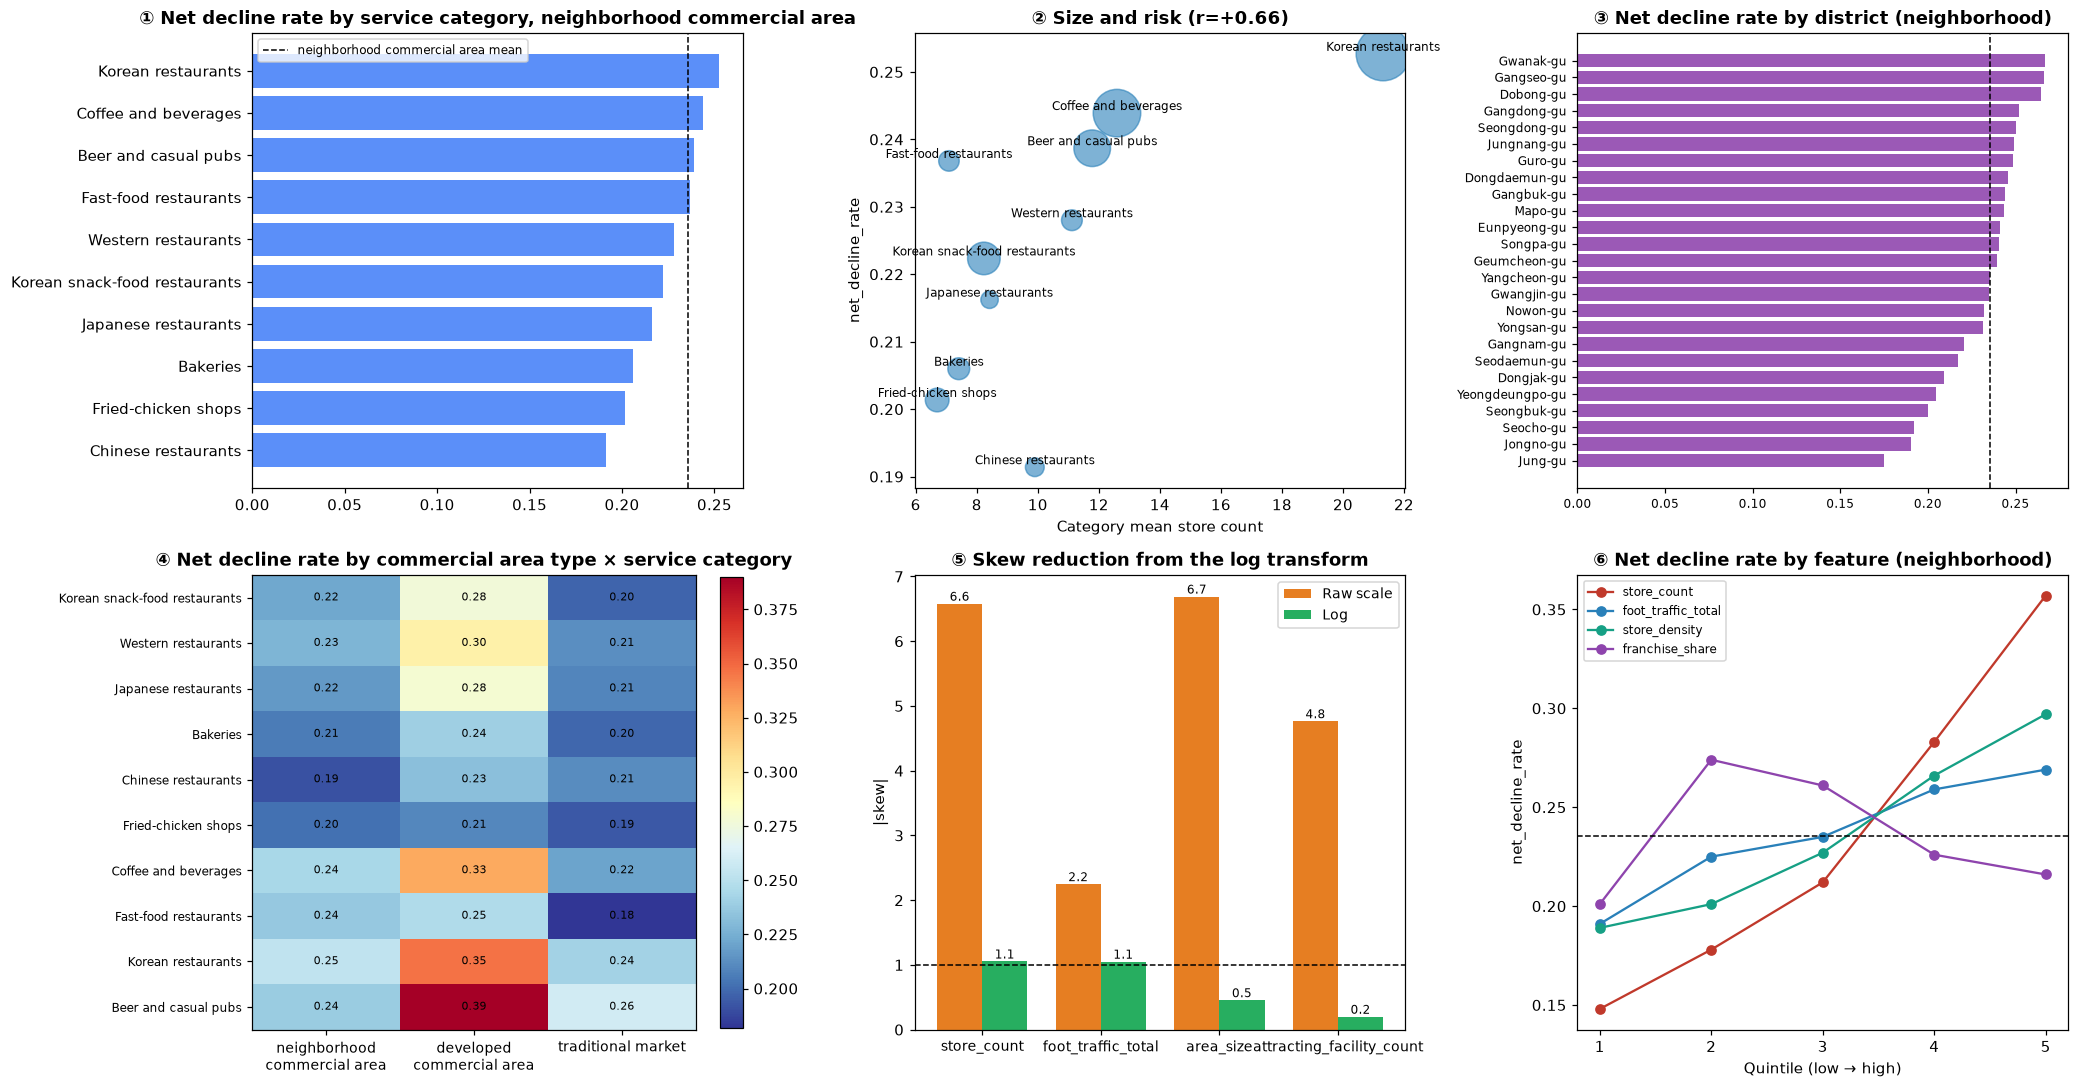

In [14]:
fig, ax = plt.subplots(2, 3, figsize=(19, 10))

# ① Net decline rate by service category (neighborhood)
s = prof["net_decline_rate"].sort_values()
ax[0,0].barh(s.index, s.values, color="#5b8ff9")
ax[0,0].axvline(gm["y"].mean(), ls="--", c="k", lw=1, label=f"{TARGET_TYPE} mean")
ax[0,0].set_title(f"① Net decline rate by service category, {TARGET_TYPE}", weight="bold")
ax[0,0].legend(fontsize=8)

# ② Size vs risk
ax[0,1].scatter(prof["mean_stores"], prof["net_decline_rate"], s=prof["n_cells"]/8, alpha=.6, c="#2980b9")
for i, row in prof.iterrows():
    ax[0,1].annotate(i, (row["mean_stores"], row["net_decline_rate"]), fontsize=8, ha="center", va="bottom")
ax[0,1].set_xlabel("Category mean store count"); ax[0,1].set_ylabel("net_decline_rate")
ax[0,1].set_title(f"② Size and risk (r={r:+.2f})", weight="bold")

# ③ By district
s = gu["net_decline_rate"].sort_values()
ax[0,2].barh(s.index, s.values, color="#9b59b6")
ax[0,2].axvline(gm["y"].mean(), ls="--", c="k", lw=1)
ax[0,2].tick_params(labelsize=8)
ax[0,2].set_title("③ Net decline rate by district (neighborhood)", weight="bold")

# ④ Commercial area type × service category heatmap
hm = piv[["neighborhood commercial area", "developed commercial area", "traditional market"]]
im = ax[1,0].imshow(hm.values, cmap="RdYlBu_r", aspect="auto")
ax[1,0].set_xticks(range(hm.shape[1])); ax[1,0].set_xticklabels([str(c).replace(" commercial area", "\ncommercial area") for c in hm.columns], fontsize=9)
ax[1,0].set_yticks(range(hm.shape[0])); ax[1,0].set_yticklabels(hm.index, fontsize=8)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax[1,0].text(j, i, f"{hm.values[i,j]:.2f}", ha="center", va="center", fontsize=7)
ax[1,0].set_title("④ Net decline rate by commercial area type × service category", weight="bold")
fig.colorbar(im, ax=ax[1,0], fraction=.046)

# ⑤ How much the log transform reduced skew
pairs = list(zip(raw_cols, COVARIATES))
sk_raw = [abs(d[a].skew()) for a, _ in pairs]
sk_log = [abs(d[b].skew()) for _, b in pairs]
xp = np.arange(len(pairs)); w = 0.38
ax[1,1].bar(xp - w/2, sk_raw, w, label="Raw scale", color="#e67e22")
ax[1,1].bar(xp + w/2, sk_log, w, label="Log", color="#27ae60")
for k, (a, b) in enumerate(zip(sk_raw, sk_log)):
    ax[1,1].text(xp[k]-w/2, a, f"{a:.1f}", ha="center", va="bottom", fontsize=8)
    ax[1,1].text(xp[k]+w/2, b, f"{b:.1f}", ha="center", va="bottom", fontsize=8)
ax[1,1].axhline(1, ls="--", c="k", lw=1)
ax[1,1].set_xticks(xp)
ax[1,1].set_xticklabels([a for a, _ in pairs], fontsize=9)
ax[1,1].set_ylabel("|skew|")
ax[1,1].set_title("⑤ Skew reduction from the log transform", weight="bold")
ax[1,1].legend(fontsize=9)

# ⑥ Net decline rate by quintile
for v, c in [("store_count", "#c0392b"), ("foot_traffic_total", "#2980b9"),
             ("store_density", "#16a085"), ("franchise_share", "#8e44ad")]:
    ax[1,2].plot(range(1, 6), quintile_profile(gm, v).values, marker="o", label=v, color=c)
ax[1,2].axhline(gm["y"].mean(), ls="--", c="k", lw=1)
ax[1,2].set_xticks(range(1, 6)); ax[1,2].set_xlabel("Quintile (low → high)")
ax[1,2].set_ylabel("net_decline_rate")
ax[1,2].set_title("⑥ Net decline rate by feature (neighborhood)", weight="bold"); ax[1,2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG / "step4_basic_eda.png", dpi=130)
plt.show()

## 4-9. Summary — what to hand over to the next steps

In [15]:
print("[To hand over to STEP 5]")
print(f"  Treated-group candidate : {prof['net_decline_rate'].idxmax()} "
      f"({prof['net_decline_rate'].max():.1%}, gap to 2nd "
      f"{(prof['net_decline_rate'].max()-prof['net_decline_rate'].nlargest(2).iloc[1])*100:+.1f} pp)")
print(f"  Size<->risk correlation : r = {r:+.3f}")
print(f"  Matching covariates     : {', '.join(COVARIATES)}")
print()
print("[To hand over to STEP 7 (sub-question 2)]")
print(f"  Sales-observed sample   : {gm['sales_observed'].mean():.1%} (neighborhood)")
print("  Candidate variables     : store_density, food_service_share, franchise_share, sales_per_store, district fixed effects")
print()
print("[To hand over to STEP 8 (H1)]")
print(f"  Service category with the largest gap between commercial area types: "
      f"{piv['row_max_diff'].idxmax()} ({(piv['row_max_diff'].max())*100:.1f} pp)")
print(f"[Saved] figures/step4_basic_eda.png")

[To hand over to STEP 5]
  Treated-group candidate : Korean restaurants (25.3%, gap to 2nd +0.9 pp)
  Size<->risk correlation : r = +0.657
  Matching covariates     : log_store_count, log_foot_traffic, log_area_size, log_attracting_facilities

[To hand over to STEP 7 (sub-question 2)]
  Sales-observed sample   : 90.9% (neighborhood)
  Candidate variables     : store_density, food_service_share, franchise_share, sales_per_store, district fixed effects

[To hand over to STEP 8 (H1)]
  Service category with the largest gap between commercial area types: Beer and casual pubs (15.1 pp)
[Saved] figures/step4_basic_eda.png


---

## What to do in STEP 5

- Narrow down to neighborhood commercial areas and **let the data decide the treated group** by net decline rate per service category
- Simple gap → scale confounding diagnosis (fixing the size stratum) → SMD → common support → cross-sectional chi-square
- A large SMD **before** matching is itself evidence that "the two groups started under different conditions", and it is why PSM is needed